# Mobile Game Player Spending Segmentation
## 02 — Data cleaning and quality review

### Project objective
NovaPlay Studios operates a free-to-play mobile game and uses in-app purchases as a key revenue stream. The business objective is to increase IAP revenue by **15% within three months of deploying the predictive ML model** through more relevant player offers. This project prepares demographic and early-gameplay data for a supervised model that predicts a new player's likely spending segment within the first **30-day period**: **Minnow** (low or no spending), **Dolphin** (moderate spending), or **Whale** (high spending), so the marketing team can tailor offers before month-end.

### Purpose of this notebook
Prepare and quality-check the player dataset before modeling.The cleaned output is **`02_clean_data.csv`**. UserID is retained for record checks, not as a model feature. InAppPurchaseAmount is retained for data-quality review, not as a predictor of a segment defined by spending.

This notebook follows a repeatable data-cleaning workflow:

1. Load and inspect the generated CSV.
2. Measure missing values and duplicates before changing anything.
3. Standardize data types so numeric and date values can be analyzed.
4. Visualize IQR outlier candidates and apply documented business rules.
5. Standardize labels, handle missing values, remove exact duplicates, and validate the result.

## 1. Load the generated dataset

Use the generated CSV `mobile_game_players_expanded_dirty.csv`. The code first checks for that exact filename in the Colab working folder; only if it is not there will it request an upload.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

INPUT_FILE = Path('mobile_game_players_expanded_dirty.csv')
if INPUT_FILE.exists():
    input_file = INPUT_FILE
else:
    from google.colab import files
    uploaded = files.upload()
    if not uploaded:
        raise FileNotFoundError('No file was uploaded. Run the generation notebook first or upload mobile_game_players_expanded_dirty.csv.')
    if INPUT_FILE.name in uploaded:
        input_file = Path(INPUT_FILE.name)
    else:
        csv_files = [name for name in uploaded if name.lower().endswith('.csv')]
        if len(csv_files) != 1:
            raise FileNotFoundError(f'Upload exactly {INPUT_FILE.name}; received: {list(uploaded)}')
        input_file = Path(csv_files[0])

df_raw = pd.read_csv(input_file)
df = df_raw.copy()
print('Loaded file:', input_file)
print('Rows and columns:', df.shape)
if len(df) < 200_000:
    raise ValueError(f'Only {len(df):,} rows loaded. Check that you selected the expanded dirty dataset.')
display(df.head())


Loaded file: mobile_game_players_expanded_dirty.csv
Rows and columns: (250000, 23)


,UserID,Age,Gender,Country,Device,GameGenre,SessionCount,AverageSessionLength,SpendingSegment,InAppPurchaseAmount,...,AcquisitionChannel,InstallDate,ActiveDays30d,PlayerLevel30d,AdsWatched30d,SocialActions30d,GuildMember,PushNotificationsOptIn,PurchaseCount30d,WinRate
0,PLAYER005364744676376,49.0,Male,Norway,Android,Battle Royale,9.0,12.83,Minnow,11.4,...,Organic,2035-01-01,5.0,4,7,1,No,No,0,0.728
1,PLAYER447523025485744,15.0,Male,Switzerland,iOS,Action RPG,11.0,19.39,Minnow,6.37,...,Cross-promotion,2023-12-19 00:00:00,3.0,4,6,3,No,Yes,0,0.183
2,PLAYER445146626174337,23.0,Male,China,Android,Fighting,9.0,8.87,Minnow,15.81,...,Cross-promotion,2024-06-03 00:00:00,5.0,5,4,5,No,No,2,0.384
3,PLAYER673007615056419,31.0,Male,Mexico,Android,Racing,12.0,NaN,Minnow,13.49,...,Referral,2024-04-26 00:00:00,8.0,8,8,1,Yes,No,0,0.265
4,PLAYER316428408427736,37.0,Female,India,Android,Battle Royale,10.0,15.23,Minnow,10.86,...,Referral,2023-10-02 00:00:00,4.0,4,5,3,No,No,0,0.285


## 2. Initial inspection — understand before editing

Check column names, data types, missing values, exact duplicates, and basic numeric summaries. This is the baseline for comparing before and after cleaning.

In [2]:
print('Dataset shape:', df.shape)
print('Columns:', df.columns.tolist())
print('Exact duplicate rows:', int(df.duplicated().sum()))

print('Column types and non-missing counts:')
df.info()

missing_before = df.isna().sum().sort_values(ascending=False)
display(missing_before.to_frame('missing_rows'))

print('Numeric summary (raw types that pandas already recognizes):')
display(df.describe())


Dataset shape: (250000, 23)
Columns: ['UserID', 'Age', 'Gender', 'Country', 'Device', 'GameGenre', 'SessionCount', 'AverageSessionLength', 'SpendingSegment', 'InAppPurchaseAmount', 'FirstPurchaseDaysAfterInstall', 'PaymentMethod', 'LastPurchaseDate', 'AcquisitionChannel', 'InstallDate', 'ActiveDays30d', 'PlayerLevel30d', 'AdsWatched30d', 'SocialActions30d', 'GuildMember', 'PushNotificationsOptIn', 'PurchaseCount30d', 'WinRate']
Exact duplicate rows: 2500
Column types and non-missing counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 23 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   UserID                         250000 non-null  object 
 1   Age                            239004 non-null  float64
 2   Gender                         240600 non-null  object 
 3   Country                        236454 non-null  object 
 4   Device                

,missing_rows
FirstPurchaseDaysAfterInstall,39890
PaymentMethod,22011
InAppPurchaseAmount,17079
Country,13546
AcquisitionChannel,12506
LastPurchaseDate,11263
Age,10996
AverageSessionLength,9890
Gender,9400
Device,4992


Numeric summary (raw types that pandas already recognizes):


,Age,SessionCount,FirstPurchaseDaysAfterInstall,ActiveDays30d,PlayerLevel30d,AdsWatched30d,SocialActions30d,PurchaseCount30d,WinRate
count,239004.000000,245010.000000,210110.000000,246247.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000
mean,33.446093,10.341766,15.391904,5.391712,6.117408,6.140392,2.948408,0.505752,0.401708
std,12.413260,4.406369,8.945679,2.368180,2.831788,2.868603,1.985163,0.809826,0.157408
min,-9.000000,-29.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,23.000000,7.000000,8.000000,4.000000,4.000000,4.000000,1.000000,0.000000,0.289000
50%,33.000000,10.000000,16.000000,5.000000,6.000000,6.000000,3.000000,0.000000,0.394000
75%,44.000000,13.000000,23.000000,7.000000,8.000000,8.000000,4.000000,1.000000,0.506000
max,66.000000,44.000000,30.000000,20.000000,27.000000,22.000000,19.000000,9.000000,1.996419


## 3. Missing-value audit — measure and visualize

The bar chart shows which original columns have the most missing values. At this point, do not fill them yet: some values may become missing during numeric/date conversion, and the cleaning decision depends on the column's meaning.

,missing_rows,missing_percent
FirstPurchaseDaysAfterInstall,39890,15.96
PaymentMethod,22011,8.80
InAppPurchaseAmount,17079,6.83
Country,13546,5.42
AcquisitionChannel,12506,5.00
LastPurchaseDate,11263,4.51
Age,10996,4.40
AverageSessionLength,9890,3.96
Gender,9400,3.76
Device,4992,2.00


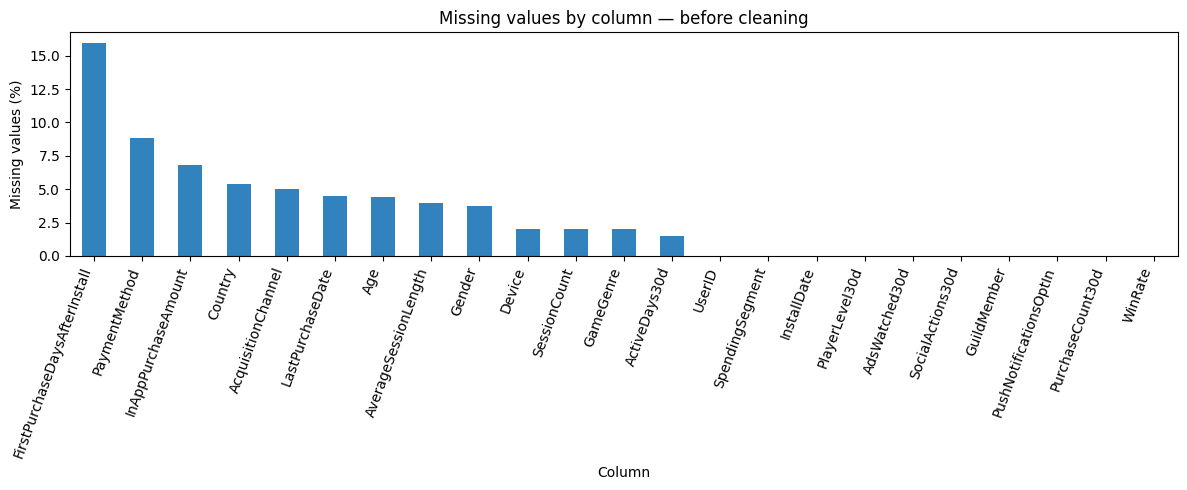

In [3]:
missing_summary = pd.DataFrame({
    'missing_rows': df.isna().sum(),
    'missing_percent': (df.isna().mean() * 100).round(2),
})
missing_summary = missing_summary.sort_values('missing_percent', ascending=False)
display(missing_summary)

plt.figure(figsize=(12, 5))
missing_summary['missing_percent'].plot.bar(color='#3182bd')
plt.title('Missing values by column — before cleaning')
plt.xlabel('Column')
plt.ylabel('Missing values (%)')
plt.xticks(rotation=70, ha='right')
plt.tight_layout()
plt.show()


### Missing-value decision — why we will not fill every column the same way

- **Target (`SpendingSegment`):** a supervised model cannot learn a missing target label. Standardize the labels; remove rows only if the target is still missing. Never invent a target.
- **Numeric predictors:** convert malformed values to missing, then use the median. The median is less affected by extreme values than the mean.
- **Categorical predictors:** use an explicit `Unknown` / `Not recorded` category rather than guessing a player's answer.
- **Dates:** do not invent a date just to make the file look complete. Keep missing dates as `NaT` and report them; if a later model needs dates, handle them in a time-aware feature pipeline.

These are transparent project decisions, not universal rules. Review them with the project requirements before final submission.

## 4. Standardize formats so values can be analyzed

The generator deliberately mixes date formats, including ISO timestamps with times. The parser below recognizes each documented format explicitly, so valid dates remain dates rather than silently turning into `NaT`. Invalid strings stay unavailable and are counted.


In [4]:
# Convert session duration to minutes. Values like '600 sec' become 10 minutes.
duration_text = df['AverageSessionLength'].astype('string').str.strip()
seconds_text = duration_text.str.extract(r'^([0-9.]+)\s*sec$', expand=False)
duration_number = pd.to_numeric(duration_text, errors='coerce')
seconds_mask = seconds_text.notna()
duration_number.loc[seconds_mask] = (
    pd.to_numeric(seconds_text[seconds_mask], errors='coerce') / 60
)
df['AverageSessionLength'] = duration_number

# Remove currency symbols and commas before converting purchase amount to numbers.
amount_text = df['InAppPurchaseAmount'].astype('string').str.replace('$', '', regex=False)
amount_text = amount_text.str.replace(',', '', regex=False).str.strip()
df['InAppPurchaseAmount'] = pd.to_numeric(amount_text, errors='coerce')

# Convert numeric fields. Non-numeric strings become unavailable for the imputation step.
numeric_columns = [
    'Age', 'SessionCount', 'FirstPurchaseDaysAfterInstall', 'ActiveDays30d',
    'PlayerLevel30d', 'AdsWatched30d', 'SocialActions30d', 'PurchaseCount30d', 'WinRate'
]
for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors='coerce')

# Explicit parser for formats written by the generator, including ISO timestamps.
def parse_mixed_date(series):
    text = series.astype('string').str.strip().str.replace('T', ' ', regex=False)
    result = pd.Series(pd.NaT, index=series.index, dtype='datetime64[ns]')
    supported_formats = [
        '%Y-%m-%d %H:%M:%S.%f', '%Y-%m-%d %H:%M:%S', '%Y-%m-%d %H:%M', '%Y-%m-%d',
        '%m/%d/%Y %H:%M:%S', '%m/%d/%Y',
        '%d-%m-%Y %H:%M:%S', '%d-%m-%Y'
    ]
    for date_format in supported_formats:
        parsed = pd.to_datetime(text, format=date_format, errors='coerce')
        result = result.fillna(parsed)
    # A fallback handles other unambiguous ISO formats while the exact patterns above
    # protect the intentionally day-first strings from month/day swapping.
    try:
        remaining = result.isna() & text.notna()
        if remaining.any():
            parsed = pd.to_datetime(text.loc[remaining], format='mixed', errors='coerce', dayfirst=False)
            result.loc[remaining] = parsed
    except (TypeError, ValueError):
        pass
    return result

df['InstallDate'] = parse_mixed_date(df['InstallDate'])
df['LastPurchaseDate'] = parse_mixed_date(df['LastPurchaseDate'])
print('Parsed numeric and date columns.')
print('AverageSessionLength unit: minutes')
print('Date column types:', df[['InstallDate', 'LastPurchaseDate']].dtypes.to_dict())
print('InstallDate parse coverage before validity checks:', f"{df['InstallDate'].notna().mean():.2%}")


Parsed numeric and date columns.
AverageSessionLength unit: minutes
Date column types: {'InstallDate': dtype('<M8[ns]'), 'LastPurchaseDate': dtype('<M8[ns]')}
InstallDate parse coverage before validity checks: 100.00%


## 5. Outlier analysis — IQR table and boxplots

The IQR fences (Q1 − 1.5×IQR and Q3 + 1.5×IQR) flag statistical candidates. The plots help locate them. We will not automatically delete every IQR candidate: unusual but possible players should remain in the data.

,Q1,Q3,IQR,lower_fence,upper_fence,IQR_candidate_count
column,,,,,,
Age,23.00,44.00,21.00,-8.50,75.50,100
SessionCount,7.00,13.00,6.00,-2.00,22.00,3430
AverageSessionLength,12.44,27.37,14.93,-9.95,49.76,692
ActiveDays30d,4.00,7.00,3.00,-0.50,11.50,2780
PlayerLevel30d,4.00,8.00,4.00,-2.00,14.00,2567
PurchaseCount30d,0.00,1.00,1.00,-1.50,2.50,7253


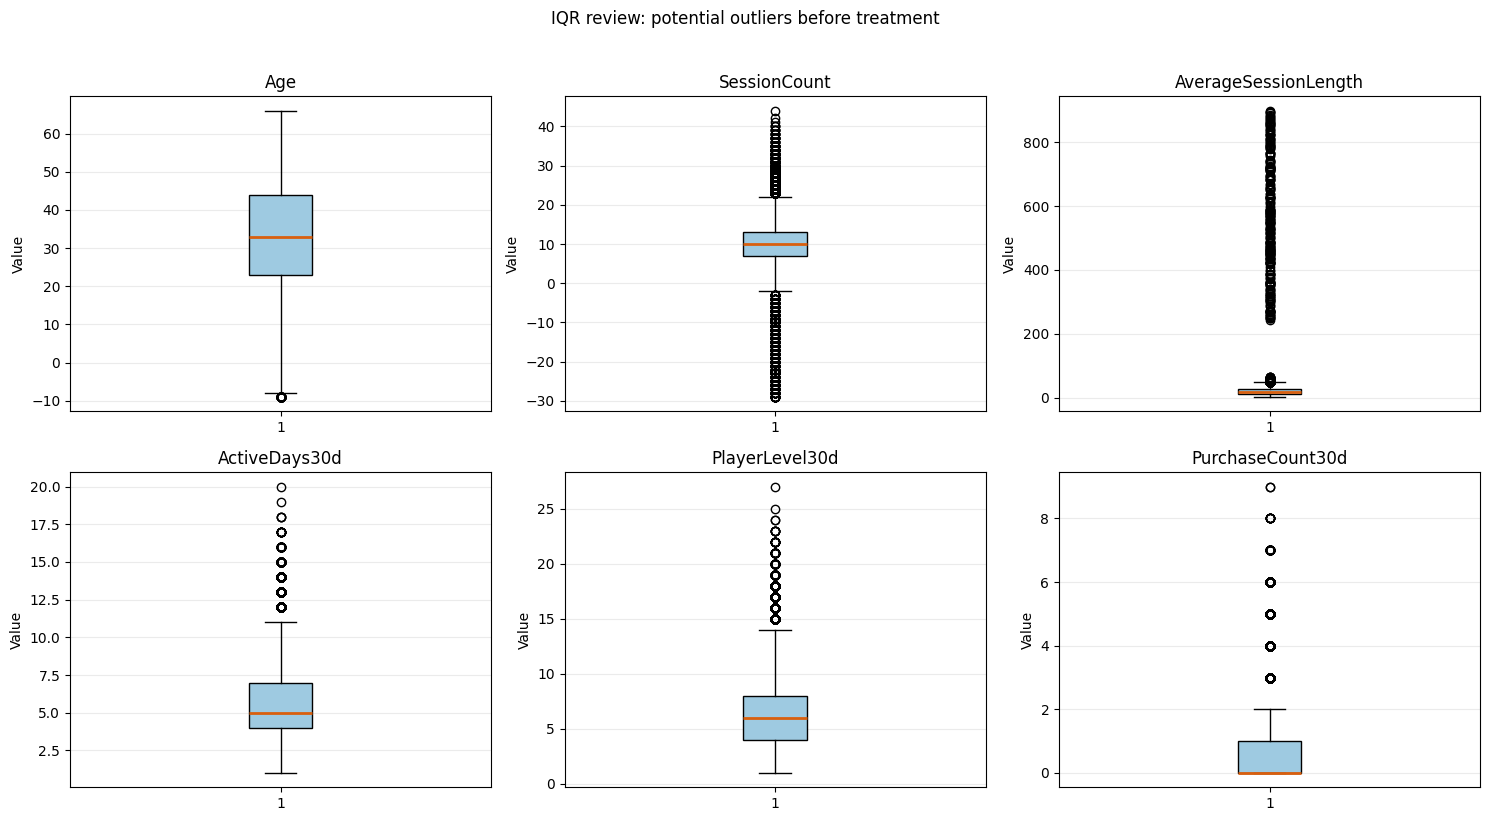

In [5]:
outlier_columns = [
    'Age', 'SessionCount', 'AverageSessionLength', 'ActiveDays30d',
    'PlayerLevel30d', 'PurchaseCount30d'
]

outlier_rows = []
for column in outlier_columns:
    values = df[column].dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    mask = (df[column] < lower_fence) | (df[column] > upper_fence)
    outlier_rows.append({
        'column': column, 'Q1': q1, 'Q3': q3, 'IQR': iqr,
        'lower_fence': lower_fence, 'upper_fence': upper_fence,
        'IQR_candidate_count': int(mask.sum()),
    })

outlier_summary = pd.DataFrame(outlier_rows).set_index('column')
display(outlier_summary.round(2))

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, column in zip(axes.flat, outlier_columns):
    ax.boxplot(df[column].dropna(), vert=True, patch_artist=True,
               boxprops={'facecolor': '#9ecae1'},
               medianprops={'color': '#d95f0e', 'linewidth': 2})
    ax.set_title(column)
    ax.set_ylabel('Value')
    ax.grid(axis='y', alpha=.25)
plt.suptitle('IQR review: potential outliers before treatment', y=1.02)
plt.tight_layout()
plt.show()


### Outlier decision — combine statistical flags with domain logic

**Decision for this dataset:**

- Do not remove a row solely because IQR marked it. IQR depends on the distribution and can flag valid heavy players.
- Treat clearly impossible values as invalid: negative age, negative session count, negative activity counts, and win rate outside 0–1 become missing.
- Treat an average session length above 240 minutes (four hours) as implausible for an *average individual session* in this project and mark it missing rather than deleting the player. This is an explicit project threshold; change it if you have a source-backed business definition.
- Keep other IQR candidates for now. Review them with subject knowledge before capping or removing them.

Marking a bad measurement as missing preserves the player's other useful information and makes the decision auditable.

In [6]:
# Apply only the explicit validity rules described above.
invalid_counts = {}

invalid_age = (df['Age'] < 0) | (df['Age'] > 100)
invalid_counts['Age outside 0-100'] = int(invalid_age.sum())
df.loc[invalid_age, 'Age'] = np.nan

invalid_sessions = df['SessionCount'] < 0
invalid_counts['Negative SessionCount'] = int(invalid_sessions.sum())
df.loc[invalid_sessions, 'SessionCount'] = np.nan

nonnegative_columns = ['FirstPurchaseDaysAfterInstall', 'ActiveDays30d', 'PlayerLevel30d', 'AdsWatched30d', 'SocialActions30d', 'PurchaseCount30d']
for column in nonnegative_columns:
    invalid = df[column] < 0
    invalid_counts[f'Negative {column}'] = int(invalid.sum())
    df.loc[invalid, column] = np.nan

invalid_active_days = df['ActiveDays30d'] > 30
invalid_counts['ActiveDays30d above 30'] = int(invalid_active_days.sum())
df.loc[invalid_active_days, 'ActiveDays30d'] = np.nan

invalid_duration = (df['AverageSessionLength'] <= 0) | (df['AverageSessionLength'] > 240)
invalid_counts['AverageSessionLength <= 0 or > 240 min'] = int(invalid_duration.sum())
df.loc[invalid_duration, 'AverageSessionLength'] = np.nan

invalid_win_rate = (df['WinRate'] < 0) | (df['WinRate'] > 1)
invalid_counts['WinRate outside 0-1'] = int(invalid_win_rate.sum())
df.loc[invalid_win_rate, 'WinRate'] = np.nan

display(pd.Series(invalid_counts, name='values_marked_missing').to_frame())


,values_marked_missing
Age outside 0-100,745
Negative SessionCount,496
Negative FirstPurchaseDaysAfterInstall,0
Negative ActiveDays30d,0
Negative PlayerLevel30d,0
Negative AdsWatched30d,0
Negative SocialActions30d,0
Negative PurchaseCount30d,0
ActiveDays30d above 30,0
AverageSessionLength <= 0 or > 240 min,251


## 6. Check date logic

The generator intentionally inserts one future installation date. It should be the only invalid install date. Installation should not occur after a recorded last purchase; investigate such pairs and mark the inconsistent event date unavailable without deleting the player row.


In [7]:
# Use the fixed end of the generated data window for a reproducible date check.
REFERENCE_DATE = pd.Timestamp('2025-08-13')
future_install = df['InstallDate'] > REFERENCE_DATE
future_last_purchase = df['LastPurchaseDate'] > REFERENCE_DATE
install_after_purchase = (
    df['InstallDate'].notna() & df['LastPurchaseDate'].notna()
    & (df['InstallDate'] > df['LastPurchaseDate'])
)
print('Install dates after the generated-data reference date:', int(future_install.sum()))
print('Last-purchase dates after the generated-data reference date:', int(future_last_purchase.sum()))
print('Install dates later than last-purchase dates:', int(install_after_purchase.sum()))
# The single future date is a deliberate quality issue; mark the date unavailable, not the player row.
df.loc[future_install, 'InstallDate'] = pd.NaT
df.loc[future_last_purchase, 'LastPurchaseDate'] = pd.NaT
# A last purchase before install is inconsistent; preserve the row but mark the bad purchase date unavailable.
df.loc[install_after_purchase, 'LastPurchaseDate'] = pd.NaT
install_coverage = df['InstallDate'].notna().mean()
print('InstallDate coverage after validity checks:', f'{install_coverage:.2%}')
if install_coverage < 0.99:
    examples = df_raw.loc[df['InstallDate'].isna(), 'InstallDate'].head(5).tolist() if 'InstallDate' in df_raw else []
    raise ValueError(f'Only {install_coverage:.1%} of InstallDate values parsed. Stop here and inspect date formats; do not export a broken cleaned file. Examples: {examples}')


Install dates after the generated-data reference date: 1
Last-purchase dates after the generated-data reference date: 0
Install dates later than last-purchase dates: 1
InstallDate coverage after validity checks: 100.00%


## 7. Standardize category labels

Trim extra spaces and normalize spelling/capitalization. Map known aliases to one canonical label. Keep unexpected values visible rather than silently forcing them into a category.

In [8]:
# Normalize simple labels by trimming spaces and using consistent capitalization.
category_columns = [
    'Gender', 'Country', 'Device', 'GameGenre', 'SpendingSegment',
    'PaymentMethod', 'AcquisitionChannel', 'GuildMember', 'PushNotificationsOptIn'
]
for column in category_columns:
    df[column] = df[column].astype('string').str.strip()

# Normalize the target labels explicitly.
df['SpendingSegment'] = df['SpendingSegment'].str.lower().map({
    'minnow': 'Minnow', 'dolphin': 'Dolphin', 'whale': 'Whale'
})

# Normalize gender and common country aliases (including the intentionally inconsistent forms).
gender_values = df['Gender'].str.lower().map({
    'male': 'Male', 'female': 'Female', 'other': 'Other', 'non-binary': 'Non-binary'
})
df['Gender'] = gender_values.fillna(df['Gender'].str.title())

country_text = df['Country'].str.lower().str.replace(r'\s+', ' ', regex=True).str.strip()
country_aliases = {
    'usa': 'United States', 'us': 'United States', 'united states': 'United States',
    'uk': 'United Kingdom', 'united kingdom': 'United Kingdom',
    'uae': 'United Arab Emirates', 'united arab emirates': 'United Arab Emirates'
}
df['Country'] = country_text.map(country_aliases).fillna(country_text.str.title())

# Normalize device names and common payment-method variations.
df['Device'] = df['Device'].str.lower().map({'android': 'Android', 'ios': 'iOS'}).fillna(df['Device'])
df['PaymentMethod'] = df['PaymentMethod'].str.lower().str.replace(' ', '', regex=False).map({
    'paypal': 'PayPal', 'creditcard': 'Credit Card', 'debitcard': 'Debit Card',
    'applepay': 'Apple Pay', 'googlepay': 'Google Pay'
}).fillna(df['PaymentMethod'])

# Normalize known genre variations.
df['GameGenre'] = df['GameGenre'].str.lower().map({
    'battleroyale': 'Battle Royale', 'battle royale': 'Battle Royale',
    'action rpg': 'Action RPG'
}).fillna(df['GameGenre'])

print('Spending segment values after standardization:')
print(df['SpendingSegment'].value_counts(dropna=False))
print('Device values after standardization:')
print(df['Device'].value_counts(dropna=False).head(10))


Spending segment values after standardization:
SpendingSegment
Minnow     210411
Dolphin     34017
Whale        5572
Name: count, dtype: int64
Device values after standardization:
Device
Android    143495
iOS        101513
<NA>         4992
Name: count, dtype: int64


## 8. Duplicate records — measure, decide, remove

The generator intentionally appended exact duplicate rows. In this project, exact duplicates are not separate players or events, so remove them. If duplicates represented repeated legitimate transactions in another dataset, the decision would be different.

In [9]:
duplicate_count_before = int(df.duplicated().sum())
print('Exact duplicates before removal:', duplicate_count_before)

df = df.drop_duplicates().copy()
df = df.reset_index(drop=True)
rows_after_deduplication = len(df)
print('Rows after duplicate removal:', len(df))
print('Exact duplicates after removal:', int(df.duplicated().sum()))


Exact duplicates before removal: 2500
Rows after duplicate removal: 247500
Exact duplicates after removal: 0


## 9. Handle remaining missing values

First review the missingness after parsing and invalid-value checks. Then apply a simple, explainable policy: median for numeric fields, `Unknown` for categorical predictors, do not invent target labels, and retain missing dates as `NaT`.

,missing_rows,missing_percent
FirstPurchaseDaysAfterInstall,39494,15.96
PaymentMethod,21783,8.80
InAppPurchaseAmount,16913,6.83
Country,13416,5.42
AcquisitionChannel,12375,5.00
Age,11636,4.70
LastPurchaseDate,11157,4.51
AverageSessionLength,10136,4.10
Gender,9309,3.76
SessionCount,5441,2.20


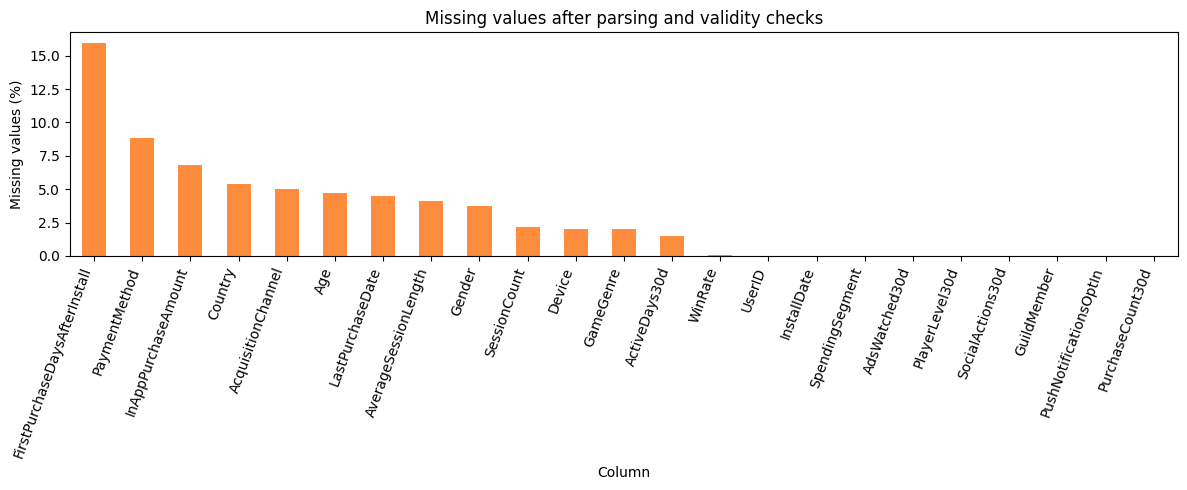

In [10]:
missing_after_validation = pd.DataFrame({
    'missing_rows': df.isna().sum(),
    'missing_percent': (df.isna().mean() * 100).round(2),
}).sort_values('missing_percent', ascending=False)
display(missing_after_validation)

plt.figure(figsize=(12, 5))
missing_after_validation['missing_percent'].plot.bar(color='#fd8d3c')
plt.title('Missing values after parsing and validity checks')
plt.xlabel('Column')
plt.ylabel('Missing values (%)')
plt.xticks(rotation=70, ha='right')
plt.tight_layout()
plt.show()


### Missing-value treatment decisions
- **Numeric fields:** median imputation is used for this coursework baseline. It is transparent and robust to skew, but a predictive model must fit imputation on the training split only.
- **Binary origin indicators:** `InAppPurchaseAmountWasMissing` and `FirstPurchaseDaysAfterInstallWasMissing` are retained as numeric `0/1` columns. They have no null values; `1` marks a value filled during cleaning and `0` marks a value retained as supplied.
- **Categorical predictors:** fill blank values with `Unknown` rather than guessing.
- **Target:** remove rows only if `SpendingSegment` remains missing or invalid; never invent a target.
- **Dates:** do not invent calendar dates. Keep only genuinely invalid/unavailable dates as `NaT`; the installation-date parse-coverage check above stops the notebook if the parser fails.


In [11]:
target_missing = df['SpendingSegment'].isna()
rows_without_target = int(target_missing.sum())
print('Rows removed because target is missing/invalid:', rows_without_target)
df = df.loc[~target_missing].copy()
rows_after_target_check = len(df)
# Preserve the state before median filling as binary indicators (never null).
for column in ['InAppPurchaseAmount', 'FirstPurchaseDaysAfterInstall']:
    df[f'{column}WasMissing'] = df[column].isna().astype('int8')
# Median imputation for numeric fields. Save the medians for documentation.
numeric_columns = df.select_dtypes(include='number').columns.tolist()
numeric_medians = df[numeric_columns].median()
df[numeric_columns] = df[numeric_columns].fillna(numeric_medians)

# Fill missing category values with a visible label rather than guessing.
categorical_columns = df.select_dtypes(include=['object', 'string', 'category']).columns.tolist()
for column in categorical_columns:
    if column != 'UserID':
        df[column] = df[column].fillna('Unknown')

print('Numeric medians used:')
display(numeric_medians.to_frame('median_used'))
print('Remaining missing values (dates are intentionally retained):')
display(df.isna().sum().to_frame('missing_rows').query('missing_rows > 0'))


Rows removed because target is missing/invalid: 0
Numeric medians used:


,median_used
Age,33.0
SessionCount,10.0
AverageSessionLength,19.92
InAppPurchaseAmount,11.91
FirstPurchaseDaysAfterInstall,16.0
ActiveDays30d,5.0
PlayerLevel30d,6.0
AdsWatched30d,6.0
SocialActions30d,3.0
PurchaseCount30d,0.0


Remaining missing values (dates are intentionally retained):


,missing_rows
LastPurchaseDate,11157
InstallDate,1


## 10. Final validation — compare before and after

Confirm dimensions, duplicates, target labels, numeric bounds, installation-date coverage, and binary indicators. With the approved 250,000-row generated file, expected output is 247,500 rows after removing the 2,500 intentional duplicates, unless target labels are genuinely invalid. No other step should silently reduce the player count.


Raw shape: (250000, 23)
Cleaned shape: (247500, 25)
Expected rows after documented removals: 247500
Rows removed in total: 2500
InstallDate valid coverage: 100.00%
Exact duplicates remaining: 0
Missing values remaining:


,missing_rows
LastPurchaseDate,11157
InstallDate,1


Target distribution after cleaning:


,players
SpendingSegment,
Minnow,208328
Dolphin,33670
Whale,5502


Numeric bounds after cleaning:


,Age,SessionCount,AverageSessionLength,WinRate
count,247500.00,247500.00,247500.0,247500.00
mean,33.54,10.39,20.38,0.40
std,11.95,4.20,9.4,0.15
min,13.00,1.00,2.87,0.00
25%,24.00,7.00,12.76,0.29
50%,33.00,10.00,19.92,0.39
75%,43.00,13.00,27.0,0.51
max,66.00,44.00,65.76,1.00


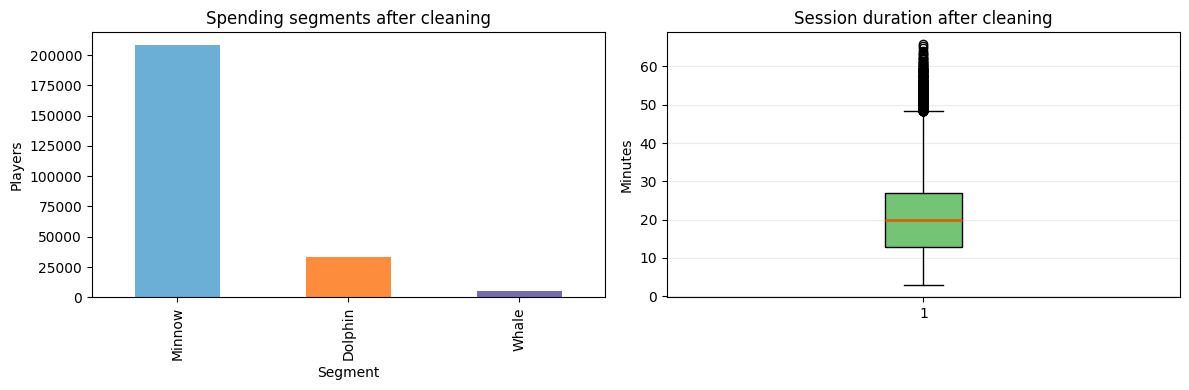

In [12]:
print('Raw shape:', df_raw.shape)
print('Cleaned shape:', df.shape)
expected_rows = rows_after_deduplication - rows_without_target
print('Expected rows after documented removals:', expected_rows)
print('Rows removed in total:', len(df_raw) - len(df))
print('InstallDate valid coverage:', f"{df['InstallDate'].notna().mean():.2%}")
assert len(df) == expected_rows, 'Unexpected row reduction: only exact duplicates and invalid targets may be removed.'
assert len(df) >= 200_000, 'Final dataset is below the required 200,000 rows.'
assert df['InstallDate'].notna().mean() >= 0.99, 'InstallDate parse coverage is unexpectedly low.'
for flag in ['InAppPurchaseAmountWasMissing', 'FirstPurchaseDaysAfterInstallWasMissing']:
    assert set(df[flag].unique()).issubset({0, 1}), f'{flag} must contain only 0/1 values.'
print('Exact duplicates remaining:', int(df.duplicated().sum()))
print('Missing values remaining:')
display(df.isna().sum().to_frame('missing_rows').query('missing_rows > 0'))

print('Target distribution after cleaning:')
display(df['SpendingSegment'].value_counts().to_frame('players'))

print('Numeric bounds after cleaning:')
display(df[['Age', 'SessionCount', 'AverageSessionLength', 'WinRate']].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df['SpendingSegment'].value_counts().reindex(['Minnow', 'Dolphin', 'Whale']).plot.bar(
    ax=axes[0], color=['#6baed6', '#fd8d3c', '#756bb1']
)
axes[0].set_title('Spending segments after cleaning')
axes[0].set_xlabel('Segment')
axes[0].set_ylabel('Players')

axes[1].boxplot(df['AverageSessionLength'], patch_artist=True,
                boxprops={'facecolor': '#74c476'},
                medianprops={'color': '#d95f0e', 'linewidth': 2})
axes[1].set_title('Session duration after cleaning')
axes[1].set_ylabel('Minutes')
axes[1].grid(axis='y', alpha=.25)
plt.tight_layout()
plt.show()


## 11. Export the cleaned dataset

Save a new file so the original dirty dataset remains unchanged. Download the cleaned CSV from Colab.

In [13]:
OUTPUT_FILE = 'mobile_game_players_cleaned.csv'
df.to_csv(OUTPUT_FILE, index=False)
print('Saved:', OUTPUT_FILE)
try:
    from google.colab import files
    files.download(OUTPUT_FILE)
except ImportError:
    print('Not running in Colab; cleaned CSV is saved in the current folder.')


Saved: mobile_game_players_cleaned.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Cleaning decisions summary
| Issue | Evidence/check | Action | Reason |
|---|---|---|---|
| Missing numeric values | Counts before/after parsing | Median imputation plus binary `0/1` origin indicators for IAP amount and first-purchase delay | Keep rows while preserving whether those two values were filled |
| Dates | Explicit mixed-format parser plus coverage assertion | Parse supported formats; flag only the deliberately future date; retain other unavailable dates | Prevent valid timestamps from silently becoming blank and prevent invented dates |
| Outliers | IQR fences and boxplots | Keep statistical candidates unless a documented business rule says invalid | IQR identifies unusual values, not automatically errors |
| Impossible values | Domain checks | Mark negative counts, invalid win rates, and implausible durations unavailable | These violate the variable's meaning |
| Inconsistent categories | Value counts and aliases | Trim/canonicalize known variants; retain unexpected values visibly | Avoid duplicate categories caused by spelling/case |
| Exact duplicates | `duplicated()` count | Drop exact duplicate rows | They were deliberately appended and do not represent extra unique players |

**Count control:** final rows must equal input rows minus exact duplicates and invalid target rows only. The expected result for this generated dataset is 247,500 rows. **Modeling note:** fit imputers after the train/test split and exclude `InAppPurchaseAmount` from predictors when it defines or reveals the target.
